# Chapter 4 — Nonlinear least squares on manifolds

Companion notebook to **Chapter 4**. We watch Gauss–Newton converge (or not), look inside Levenberg–Marquardt,
finish the camera calibration of Chapter 3, check the Laplace covariance against Monte Carlo, and see robust kernels
reject outliers.

All solvers live in `vslam.optim`. A problem only has to provide `linearize(x) -> (r, J)` (whitened residual and its
Jacobian with respect to a tangent perturbation) and `retract(x, delta)`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import calib, lie, optim, robust
from ch04_least_squares import MNT, PoseProblem, pose_scene, WIDE

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The local rate of Gauss–Newton (Theorem 4.3)

Near a minimiser, Gauss–Newton is a fixed-point iteration whose Jacobian is $-(J^\top J)^{-1}S$, where
$S=\sum_i r_i\nabla^2 r_i$ collects the second derivatives that Gauss–Newton ignores. For
$r(x)=(x+1,\ \lambda x^2+x-1)$ this is exactly $\lambda$: the error is multiplied by $\lambda$ at each step.

In [2]:
print(f"{'lambda':>7} {'observed ratio x_(k+1)/x_k':>28}")
for lam in [0.1, 0.5, 0.9, -0.5, -2.0]:
    res = optim.gauss_newton(MNT(lam), np.array([1e-3]), max_iters=6, tol=0.0)
    xs = np.array([h["x"][0] for h in res.history])
    print(f"{lam:7.1f} {np.median(xs[1:5] / xs[0:4]):28.4f}")

 lambda   observed ratio x_(k+1)/x_k
    0.1                       0.1000
    0.5                       0.4999
    0.9                       0.8990
   -0.5                      -0.5000
   -2.0                      -1.9955


## 2. Inside Levenberg–Marquardt (Section 4.3)

Calibration of the wide-angle camera of Chapter 3 from 20 views. For each LM iteration: the cost, the damping
$\lambda$, the gain ratio $\varrho$ and whether the step was accepted.

In [3]:
sigma = 0.3
board, views = calib.synthetic_views(WIDE, 20, rng, sigma, distance=0.5, spread=0.1)
px = [u for _, u in views]
cam_lm, poses, res = calib.calibrate(board, px, WIDE.width, WIDE.height, sigma, method="lm")

print(f"{'it':>3} {'cost':>12} {'lambda':>10} {'gain':>8}  accepted")
for i, h in enumerate(res.history):
    print(f"{i:3d} {h['cost']:12.2f} {h['lambda']:10.2e} {h.get('gain', np.nan):8.3f}  {h['accepted']}")

 it         cost     lambda     gain  accepted
  0     33562.67   1.00e-03      nan  True
  1     11099.13   3.33e-04    0.964  True
  2      5977.42   2.33e-04    0.835  True
  3      4271.30   2.33e-04    0.560  True
  4      2302.34   1.39e-04    0.869  True
  5      1687.60   1.29e-04    0.706  True
  6      1238.68   4.65e-05    0.931  True
  7      1120.48   3.84e-05    0.779  True
  8      1056.99   1.28e-05    0.976  True
  9      1037.40   4.27e-06    0.969  True
 10      1032.22   1.42e-06    1.005  True
 11      1031.94   4.74e-07    1.023  True
 12      1031.93   1.58e-07    1.049  True
 13      1031.93   5.27e-08    1.064  True
 14      1031.93   1.76e-08    1.066  True


## 3. The calibration, finished

The linear step of Zhang ignored distortion; the refinement estimates $f_x,f_y,c_x,c_y,k_1,k_2,p_1,p_2$ ($k_3$ held at
zero) and the 20 board poses together. The residuals left over should look like the 0.3 px noise and nothing else.

          true   estimate  std (Laplace)  error/std
 fx      458.7      457.2       1.47e+00      -0.99
 fy      457.3      456.1       1.45e+00      -0.85
 cx      367.2      368.6       1.66e+00       0.86
 cy      248.4      248.7       1.25e+00       0.23
 k1     -0.283    -0.2831       3.06e-03      -0.05
 k2      0.074    0.07379       6.58e-03      -0.03
 p1    0.00018  0.0004067       3.43e-04       0.66
 p2    1.8e-05 -0.0002418       2.86e-04      -0.91


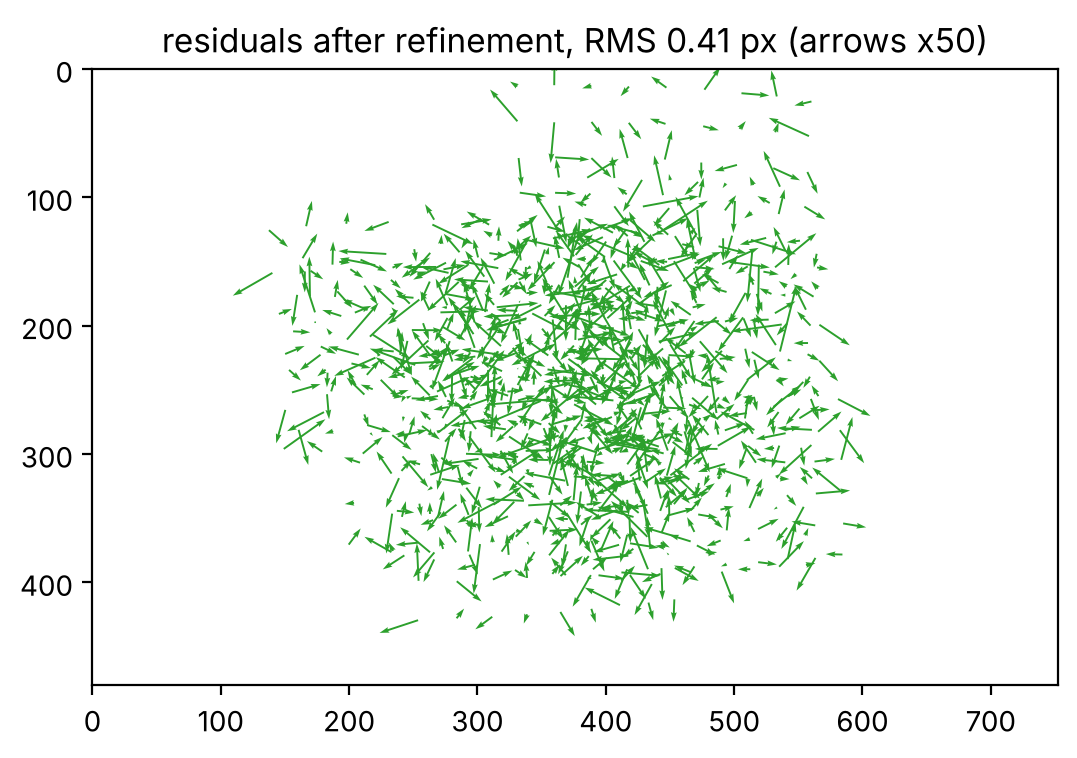

In [4]:
names = ["fx", "fy", "cx", "cy", "k1", "k2", "p1", "p2"]
pb = calib.CalibrationProblem(board, px, sigma, WIDE.width, WIDE.height, fix_k3=True)
std = np.sqrt(np.diag(optim.covariance(pb, res.x))[:8])
print(f"{'':>3} {'true':>10} {'estimate':>10} {'std (Laplace)':>14} {'error/std':>10}")
for n, t, e, s in zip(names, WIDE.params, cam_lm.params, std):
    print(f"{n:>3} {t:10.4g} {e:10.4g} {s:14.2e} {(e - t) / s:10.2f}")

r, _ = calib.CalibrationProblem(board, px, 1.0, WIDE.width, WIDE.height).linearize(res.x)
r = r.reshape(-1, 2)
obs = np.vstack(px)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.quiver(obs[:, 0], obs[:, 1], r[:, 0], r[:, 1], angles="xy", scale_units="xy", scale=0.02,
          color="tab:green", width=0.002)
ax.set_xlim(0, WIDE.width); ax.set_ylim(WIDE.height, 0); ax.set_aspect("equal")
ax.set_title(f"residuals after refinement, RMS {np.sqrt(np.mean(np.sum(r**2, 1))):.2f} px (arrows x50)");

## 4. Is the Laplace covariance right? (Proposition 4.12)

Keep the geometry of section 2 (the same 20 board poses), redraw only the pixel noise 30 times, recalibrate each
time, and compare the spread of the estimates with the standard deviations predicted by $(J^\\top J)^{-1}$ at the
single run of section 3. (About half a minute.)

In [5]:
clean = [WIDE.project(board @ T_cb[:3, :3].T + T_cb[:3, 3]) for T_cb, _ in views]   # noise-free pixels
noise_rng = np.random.default_rng(100)
ests = []
for t in range(30):
    noisy = [u + noise_rng.normal(scale=sigma, size=u.shape) for u in clean]
    c, _, _ = calib.calibrate(board, noisy, WIDE.width, WIDE.height, sigma, method="gn")
    ests.append(c.params[:8])
ests = np.array(ests)
print(f"{'':>3} {'Monte Carlo std':>16} {'predicted std':>14}")
for n, mc, pr in zip(names, ests.std(axis=0), std):
    print(f"{n:>3} {mc:16.2e} {pr:14.2e}")

     Monte Carlo std  predicted std
 fx         1.50e+00       1.47e+00
 fy         1.47e+00       1.45e+00
 cx         1.59e+00       1.66e+00
 cy         1.14e+00       1.25e+00
 k1         3.99e-03       3.06e-03
 k2         8.28e-03       6.58e-03
 p1         3.13e-04       3.43e-04
 p2         2.85e-04       2.86e-04


The two columns agree to within a few tens of percent, about what one can ask of a standard deviation estimated from
30 samples (its own relative uncertainty is about 13 % at one sigma). The prediction costs one matrix inversion.

## 5. Robust kernels see the outliers (Section 4.4)

A camera pose estimated from 100 correspondences, 30 % of which are random pixels — the kind of garbage feature
matching produces on grass. After convergence, the IRLS weights of the Cauchy kernel separate inliers from outliers
almost perfectly.

 least squares: position error 6.4482 m, 6 iterations
     Huber k=2: position error 0.0128 m, 8 iterations
    Cauchy k=2: position error 0.0016 m, 10 iterations


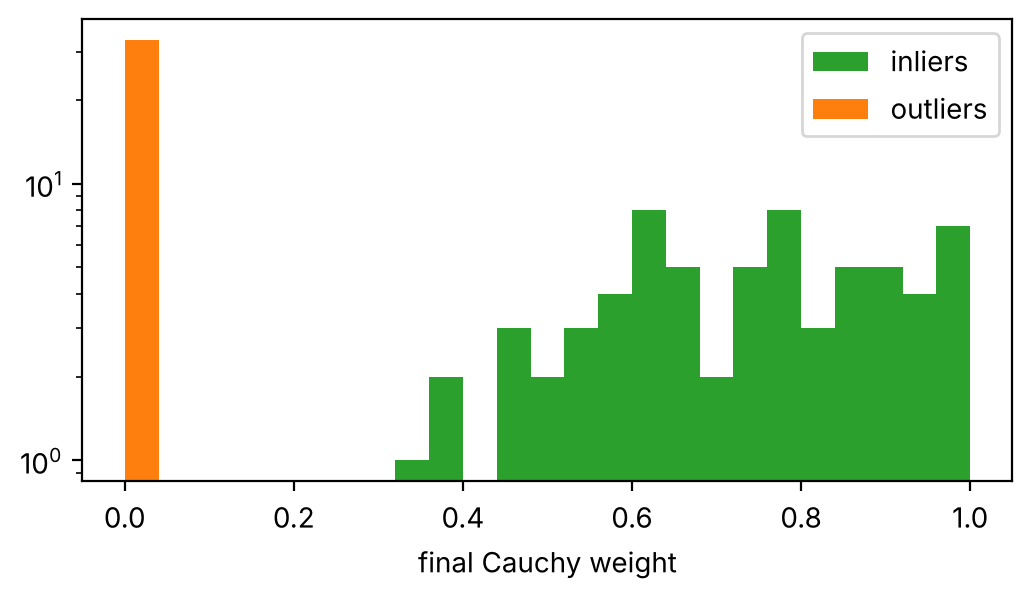

In [6]:
cam, T_true, P, z = pose_scene(np.random.default_rng(7), outlier_frac=0.3)
pred = np.array([cam.project_world(T_true, p)[0] for p in P])
is_out = np.linalg.norm(z - pred, axis=1) > 5.0          # ground truth labels
T0 = T_true @ lie.se3_exp(np.array([0.15, -0.1, 0.1, 0.02, -0.03, 0.02]))
pb = PoseProblem(cam, P, z, sigma=0.5)

for name, k in [("least squares", None), ("Huber k=2", robust.Huber(2.0)), ("Cauchy k=2", robust.Cauchy(2.0))]:
    res = optim.levenberg_marquardt(pb, T0, kernel=k)
    err = np.linalg.norm(res.x[:3, 3] - T_true[:3, 3])
    print(f"{name:>14}: position error {err:.4f} m, {res.iterations} iterations")

kernel = robust.Cauchy(2.0)
r, _ = pb.linearize(res.x)
w = kernel.weight(np.sum(r.reshape(-1, 2) ** 2, axis=1))
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist([w[~is_out], w[is_out]], bins=np.linspace(0, 1, 26), stacked=True,
        color=["tab:green", "tab:orange"], label=["inliers", "outliers"])
ax.set_yscale("log"); ax.set_xlabel("final Cauchy weight"); ax.legend();

## 6. Optimising a rotation directly (Section 4.5)

Find $R\in\mathrm{SO}(3)$ minimising $\sum_i\|R\mathbf a_i-\mathbf b_i\|^2$ with LM and the retraction
$R\oplus\boldsymbol\delta = R\,\mathrm{Exp}(\boldsymbol\delta)$, starting from a random rotation. The answer must match
the closed form of Lemma 3.14 (Kabsch/Umeyama).

In [7]:
class Rotation:
    block_size = 3
    def __init__(self, a, b): self.a, self.b = a, b
    def linearize(self, R):
        r = (self.a @ R.T - self.b).ravel()
        J = np.vstack([-R @ lie.hat(ai) for ai in self.a])     # d(R Exp(d) a)/dd = -R hat(a)
        return r, J
    def retract(self, R, d): return R @ lie.so3_exp(d)

R_true = lie.so3_exp(rng.normal(size=3))
a = rng.normal(size=(30, 3)); b = a @ R_true.T + 0.05 * rng.normal(size=(30, 3))
res = optim.levenberg_marquardt(Rotation(a, b), lie.so3_exp(np.array([2.5, -1.0, 0.5])))
print("LM iterations:", res.iterations, " costs:", res.costs.round(3))
print("LM  vs closed form:", np.abs(res.x - calib.nearest_rotation(b.T @ a)).max())

LM iterations: 9  costs: [107.29   97.401  87.107  69.632  33.489   2.925   0.096   0.094   0.094
   0.094]
LM  vs closed form: 2.64146877981819e-09


## 7. Try it yourself

* In section 2, call `calibrate(..., method="gn")` and print its history: the very first Gauss–Newton step *increases*
  the cost twenty-fold. Why can it still converge?
* In section 5, raise the outlier fraction to 60 %. Which kernel survives? Now start Cauchy from a pose 1 m away:
  what goes wrong, and what does it say about initialisation (Chapter 7)?
* Free $k_3$ (`fix_k3=False`). What happens to the predicted standard deviations of $k_1,k_2,k_3$, and why?